# 05 - Modelling

Predict `compressive_strength` (MPa) from the mix and curing age.

1. Setup and data (split, folds and features from `04_DataSplit`)
2. Baseline: every model with **default parameters**, on raw and engineered features
3. Tune the **top 3** models with Optuna
4. Monotonic constraints: check the physics, then constrained baselines and tuning
5. Predict on the test set
6. Aggregate all results, pick the best constrained and best unconstrained model, check new mix designs
7. Save both models (the app can switch between them)

**Rules**
- All comparison and tuning uses the 5 CV folds of the training set only.
- The test set is used once, at the end (section 5).
- Every model scales its inputs and learns **√strength** (the prediction is squared back), so strength can never be negative.

---
## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import PredefinedSplit, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

sys.path.insert(0, str(Path('..').resolve()))   # backend/ -> "ML.features" is importable
from ML.features import INGREDIENTS, MODEL_FEATURES, MONOTONE_DIRECTIONS, RAW_FEATURES, TARGET, add_features

warnings.filterwarnings('ignore', category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.float_format', '{:,.3f}'.format)

SEED = 42
N_TRIALS = 30   # Optuna trials per model (lower it for a quicker run)

In [2]:
data = pd.read_csv(Path('data') / 'splits.csv')
train = data[data['split'] == 'train'].reset_index(drop=True)
test = data[data['split'] == 'test'].reset_index(drop=True)
y_train, y_test = train[TARGET], test[TARGET]

FEATURE_SETS = {
    'raw': RAW_FEATURES,               # 7 ingredients + age
    'engineered': MODEL_FEATURES,      # 7 ingredients + log_age, water_binder, water_cement, total_binder
}

cv = PredefinedSplit(train['fold'])   # the 5 folds saved by 04_DataSplit
print(f'Train: {len(train)} rows   Test: {len(test)} rows   CV folds: {cv.get_n_splits()}')

Train: 804 rows   Test: 201 rows   CV folds: 5


Helpers:
- `make_model` wraps any regressor: scale the inputs, learn √strength, square the prediction back.
- `evaluate_cv` scores a model on the 5 folds (mean of the folds).

In [3]:
def square_back(p):
    return np.clip(p, 0, None) ** 2


def make_model(estimator):
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), estimator),
                                      func=np.sqrt, inverse_func=square_back, check_inverse=False)


def evaluate_cv(estimator, features):
    scores = cross_validate(make_model(estimator), train[features], y_train, cv=cv, n_jobs=-1,
                            return_train_score=True,
                            scoring={'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error',
                                     'MAE': 'neg_mean_absolute_error'})
    return {'CV_R2': scores['test_R2'].mean(), 'CV_RMSE': -scores['test_RMSE'].mean(),
            'CV_MAE': -scores['test_MAE'].mean(), 'Train_R2': scores['train_R2'].mean()}

---
## 2. Baseline models (default parameters)

Every model with its default settings, on both feature sets.

In [4]:
def baseline_models():
    return {
        'Linear Regression': LinearRegression(),
        'Ridge': Ridge(),
        'KNN': KNeighborsRegressor(),
        'SVR': SVR(),
        'Decision Tree': DecisionTreeRegressor(random_state=SEED),
        'Random Forest': RandomForestRegressor(random_state=SEED),
        'Extra Trees': ExtraTreesRegressor(random_state=SEED),
        'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
        'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=SEED),
        'XGBoost': XGBRegressor(random_state=SEED, n_jobs=1),
        'LightGBM': LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
    }


rows = []
for feature_name, features in FEATURE_SETS.items():
    for name, estimator in baseline_models().items():
        rows.append({'model': name, 'features': feature_name, **evaluate_cv(estimator, features)})

baseline = pd.DataFrame(rows).sort_values('CV_RMSE').reset_index(drop=True)
baseline['overfit_gap'] = baseline['Train_R2'] - baseline['CV_R2']
baseline

,model,features,CV_R2,CV_RMSE,CV_MAE,Train_R2,overfit_gap
0,LightGBM,engineered,0.918,4.640,3.172,0.984,0.066
1,Hist Gradient Boosting,engineered,0.917,4.643,3.183,0.984,0.067
2,Hist Gradient Boosting,raw,0.913,4.793,3.292,0.982,0.069
3,LightGBM,raw,0.911,4.819,3.312,0.981,0.070
4,XGBoost,engineered,0.907,4.943,3.175,0.998,0.091
5,Gradient Boosting,engineered,0.904,5.037,3.678,0.956,0.052
6,Extra Trees,engineered,0.901,5.102,3.294,0.998,0.097
7,Random Forest,engineered,0.901,5.110,3.588,0.984,0.084
8,XGBoost,raw,0.898,5.168,3.494,0.998,0.100
9,Extra Trees,raw,0.894,5.292,3.487,0.998,0.104


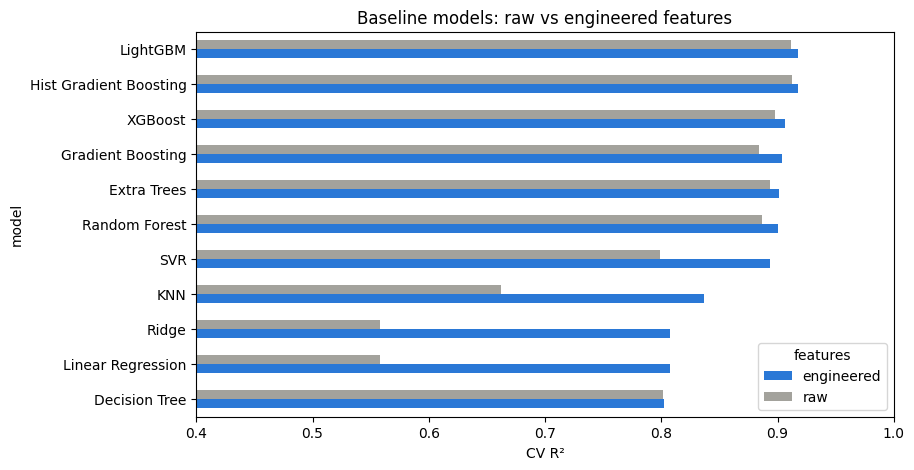

In [5]:
pivot = baseline.pivot(index='model', columns='features', values='CV_R2').sort_values('engineered')
ax = pivot.plot.barh(figsize=(9, 5), color=['#2a78d6', '#a3a29c'])
ax.set_xlim(0.4, 1.0)
ax.set_xlabel('CV R²')
ax.set_title('Baseline models: raw vs engineered features')
plt.show()

**Pick the feature set and the top 3 models.** The feature set of the best baseline is used from here on,
and the 3 best models on that feature set (lowest CV RMSE) go to tuning.

In [6]:
FEATURE_NAME = baseline.loc[0, 'features']
FEATURES = FEATURE_SETS[FEATURE_NAME]
top3 = baseline[baseline['features'] == FEATURE_NAME].head(3)['model'].tolist()

print('Feature set:', FEATURE_NAME)
print('Top 3 models:', top3)

Feature set: engineered
Top 3 models: ['LightGBM', 'Hist Gradient Boosting', 'XGBoost']


---
## 3. Hyperparameter tuning (Optuna)

Each of the top 3 models is tuned with Optuna, minimising **CV RMSE** on the same 5 folds.
`search_space` has a range for every model, so it works whichever 3 come out on top.

In [7]:
def search_space(name, trial):
    lr = lambda: trial.suggest_float('learning_rate', 0.01, 0.2, log=True)
    n_trees = lambda: trial.suggest_int('n_estimators', 200, 1500, step=100)

    if name == 'Ridge':
        return {'alpha': trial.suggest_float('alpha', 1e-3, 100, log=True)}
    if name == 'KNN':
        return {'n_neighbors': trial.suggest_int('n_neighbors', 2, 30),
                'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
                'p': trial.suggest_int('p', 1, 2)}
    if name == 'SVR':
        return {'C': trial.suggest_float('C', 0.1, 100, log=True),
                'gamma': trial.suggest_float('gamma', 1e-3, 1, log=True),
                'epsilon': trial.suggest_float('epsilon', 0.01, 0.5, log=True)}
    if name == 'Decision Tree':
        return {'max_depth': trial.suggest_int('max_depth', 3, 20),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20)}
    if name in ['Random Forest', 'Extra Trees']:
        return {'n_estimators': trial.suggest_int('n_estimators', 200, 1000, step=100),
                'max_depth': trial.suggest_int('max_depth', 4, 30),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
                'max_features': trial.suggest_float('max_features', 0.3, 1.0)}
    if name == 'Gradient Boosting':
        return {'n_estimators': n_trees(), 'learning_rate': lr(),
                'max_depth': trial.suggest_int('max_depth', 2, 8),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
                'subsample': trial.suggest_float('subsample', 0.5, 1.0)}
    if name == 'Hist Gradient Boosting':
        return {'max_iter': trial.suggest_int('max_iter', 200, 1500, step=100), 'learning_rate': lr(),
                'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 8, 64),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 3, 30),
                'l2_regularization': trial.suggest_float('l2_regularization', 1e-3, 10, log=True)}
    if name == 'XGBoost':
        return {'n_estimators': n_trees(), 'learning_rate': lr(),
                'max_depth': trial.suggest_int('max_depth', 2, 8),
                'min_child_weight': trial.suggest_float('min_child_weight', 1, 10),
                'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True)}
    if name == 'LightGBM':
        return {'n_estimators': n_trees(), 'learning_rate': lr(),
                'num_leaves': trial.suggest_int('num_leaves', 4, 64),
                'min_child_samples': trial.suggest_int('min_child_samples', 3, 30),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True)}
    raise ValueError(f'No search space for {name}')

In [8]:
# Monotonic constraints (used in section 4): +1 = strength rises with the feature, -1 = it falls, 0 = free
DIRECTIONS = {**MONOTONE_DIRECTIONS, 'age': 1}   # 'age' covers the raw feature set
CONSTRAINT_PARAM = {'Decision Tree': 'monotonic_cst', 'Random Forest': 'monotonic_cst',
                    'Extra Trees': 'monotonic_cst', 'Hist Gradient Boosting': 'monotonic_cst',
                    'XGBoost': 'monotone_constraints', 'LightGBM': 'monotone_constraints'}


def create(name, params=None, constrained=False):
    # A fresh model with the given parameters (and the physics constraints if asked)
    model = baseline_models()[name].set_params(**(params or {}))
    if constrained:
        cst = [DIRECTIONS.get(c, 0) for c in FEATURES]
        model.set_params(**{CONSTRAINT_PARAM[name]: tuple(cst) if name == 'XGBoost' else cst})
    return model


def tune(names, constrained=False):
    best_params, rows = {}, []
    for name in names:
        def objective(trial):
            return evaluate_cv(create(name, search_space(name, trial), constrained), FEATURES)['CV_RMSE']

        study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
        best_params[name] = study.best_params
        rows.append({'model': name, **evaluate_cv(create(name, study.best_params, constrained), FEATURES)})
        print(f'{name}: best CV RMSE {study.best_value:.3f} MPa   {study.best_params}')
    return best_params, pd.DataFrame(rows).set_index('model').sort_values('CV_RMSE')

In [9]:
tuned_params, tuned = tune(top3)
tuned

  0%|          | 0/30 [00:00<?, ?it/s]

LightGBM: best CV RMSE 4.212 MPa   {'n_estimators': 500, 'learning_rate': 0.129831053581539, 'num_leaves': 20, 'min_child_samples': 30, 'colsample_bytree': 0.4937070297305526, 'reg_lambda': 0.1417702261396068}


  0%|          | 0/30 [00:00<?, ?it/s]

Hist Gradient Boosting: best CV RMSE 4.389 MPa   {'max_iter': 1300, 'learning_rate': 0.03595288075279632, 'max_leaf_nodes': 24, 'min_samples_leaf': 29, 'l2_regularization': 0.08378722177845534}


  0%|          | 0/30 [00:00<?, ?it/s]

XGBoost: best CV RMSE 4.356 MPa   {'n_estimators': 1200, 'learning_rate': 0.025824825886080788, 'max_depth': 6, 'min_child_weight': 6.34887165103669, 'subsample': 0.5135883502516334, 'colsample_bytree': 0.8680089198399865, 'reg_lambda': 0.2582750503920017}


,CV_R2,CV_RMSE,CV_MAE,Train_R2
model,,,,
LightGBM,0.931,4.212,2.835,0.992
XGBoost,0.927,4.356,2.886,0.993
Hist Gradient Boosting,0.926,4.389,2.892,0.993


Baseline vs tuned (CV RMSE, MPa):

In [10]:
base_rmse = baseline[baseline['features'] == FEATURE_NAME].set_index('model')['CV_RMSE']
pd.DataFrame({'baseline': base_rmse[top3], 'tuned': tuned['CV_RMSE'][top3]}).assign(
    improvement=lambda d: d['baseline'] - d['tuned'])

,baseline,tuned,improvement
model,,,
LightGBM,4.640,4.212,0.427
Hist Gradient Boosting,4.643,4.389,0.254
XGBoost,4.943,4.356,0.587


---
## 4. Monotonic constraints

Known physics: strength should **rise** with curing age and cement, and **fall** with more water.
Unconstrained trees can learn bumps that break this (e.g. strength dropping between 28 and 56 days),
and the app's age curve and sensitivity charts would show them.

### 4.1 Physics check

On every mix design in the data:
1. **Age curve** (3 → 365 days): number of mixes where predicted strength ever falls.
2. **Min prediction** anywhere on those curves.
3. **Cement / water sweeps** at 28 days (one ingredient across its range, the rest fixed):
   % of mixes where more cement never lowers strength, and more water never raises it.

A model **passes** if no age curve falls and both sweeps are 100%.

In [11]:
mixes = data.drop_duplicates('mix_id')[INGREDIENTS].reset_index(drop=True)
AGES = [3, 7, 14, 28, 56, 90, 180, 365]


def prepare(raw):
    # raw columns -> the columns the model was trained on
    X = add_features(raw)
    X['age'] = raw['age'].to_numpy()
    return X[FEATURES]


def sweep_ok(model, feature, direction, points=25):
    xs = np.linspace(data[feature].min(), data[feature].max(), points)
    rows = mixes.loc[mixes.index.repeat(points)].assign(age=28)
    rows[feature] = np.tile(xs, len(mixes))
    curves = model.predict(prepare(rows)).reshape(len(mixes), points)
    return (np.diff(curves, axis=1) * direction >= -1e-6).all(axis=1).mean() * 100


def physics_check(model):
    rows = mixes.loc[mixes.index.repeat(len(AGES))].assign(age=np.tile(AGES, len(mixes)))
    curves = model.predict(prepare(rows)).reshape(len(mixes), len(AGES))
    result = {'falling_age_curves': int((np.diff(curves, axis=1) < -1e-6).any(axis=1).sum()),
              'min_pred_MPa': curves.min(),
              'cement_ok_%': sweep_ok(model, 'cement', +1),
              'water_ok_%': sweep_ok(model, 'water', -1)}
    result['physics_OK'] = (result['falling_age_curves'] == 0 and result['cement_ok_%'] == 100
                            and result['water_ok_%'] == 100)
    return result


checks = {name: physics_check(make_model(create(name, tuned_params[name])).fit(train[FEATURES], y_train))
          for name in top3}
pd.DataFrame(checks).T

,falling_age_curves,min_pred_MPa,cement_ok_%,water_ok_%,physics_OK
LightGBM,51,3.078,0.000,0.000,False
Hist Gradient Boosting,56,3.112,0.000,0.000,False
XGBoost,43,3.071,0.000,0.000,False


### 4.2 Constrained baselines

Models that support monotonic constraints, with default parameters plus the constraints:

| feature | direction |
|---|---|
| log_age (or age), cement, total_binder | ↑ |
| water, water_binder, water_cement | ↓ |
| slag, fly ash, superplasticizer, aggregates | free |

Every column that contains age, cement or water is constrained, so the directions hold for the raw inputs too.

In [12]:
print('Constraints:', dict(zip(FEATURES, [DIRECTIONS.get(c, 0) for c in FEATURES])))

rows = [{'model': name, **evaluate_cv(create(name, constrained=True), FEATURES)} for name in CONSTRAINT_PARAM]
baseline_c = pd.DataFrame(rows).sort_values('CV_RMSE').reset_index(drop=True)
baseline_c['overfit_gap'] = baseline_c['Train_R2'] - baseline_c['CV_R2']
baseline_c

Constraints: {'cement': 1, 'blast_furnace_slag': 0, 'fly_ash': 0, 'water': -1, 'superplasticizer': 0, 'coarse_aggregate': 0, 'fine_aggregate': 0, 'log_age': 1, 'water_binder': -1, 'water_cement': -1, 'total_binder': 1}


,model,CV_R2,CV_RMSE,CV_MAE,Train_R2,overfit_gap
0,Hist Gradient Boosting,0.917,4.650,3.310,0.970,0.052
1,LightGBM,0.914,4.736,3.356,0.968,0.055
2,XGBoost,0.914,4.738,3.259,0.986,0.071
3,Random Forest,0.763,7.958,6.109,0.831,0.068
4,Extra Trees,0.682,9.231,7.376,0.753,0.071
5,Decision Tree,0.675,9.313,7.085,0.784,0.109


### 4.3 Tune the top 3 constrained models

In [13]:
top3_c = baseline_c.head(3)['model'].tolist()
print('Top 3 constrained models:', top3_c)

tuned_params_c, tuned_c = tune(top3_c, constrained=True)
tuned_c

Top 3 constrained models: ['Hist Gradient Boosting', 'LightGBM', 'XGBoost']


  0%|          | 0/30 [00:00<?, ?it/s]

Hist Gradient Boosting: best CV RMSE 4.455 MPa   {'max_iter': 1500, 'learning_rate': 0.02250265635874823, 'max_leaf_nodes': 30, 'min_samples_leaf': 19, 'l2_regularization': 0.002127427342122125}


  0%|          | 0/30 [00:00<?, ?it/s]

LightGBM: best CV RMSE 4.348 MPa   {'n_estimators': 1000, 'learning_rate': 0.052973222430993304, 'num_leaves': 59, 'min_child_samples': 13, 'colsample_bytree': 0.4523186769048533, 'reg_lambda': 0.003399714365746141}


  0%|          | 0/30 [00:00<?, ?it/s]

XGBoost: best CV RMSE 4.382 MPa   {'n_estimators': 500, 'learning_rate': 0.04769807686713462, 'max_depth': 7, 'min_child_weight': 7.947301485797073, 'subsample': 0.9911102070867364, 'colsample_bytree': 0.7058468472391984, 'reg_lambda': 0.3567990027185111}


,CV_R2,CV_RMSE,CV_MAE,Train_R2
model,,,,
LightGBM,0.928,4.348,3.057,0.984
XGBoost,0.926,4.382,3.068,0.984
Hist Gradient Boosting,0.924,4.455,3.143,0.981


In [14]:
checks_c = {name: physics_check(make_model(create(name, tuned_params_c[name], True)).fit(train[FEATURES], y_train))
            for name in top3_c}
pd.DataFrame(checks_c).T

,falling_age_curves,min_pred_MPa,cement_ok_%,water_ok_%,physics_OK
Hist Gradient Boosting,0,1.712,100.000,100.000,True
LightGBM,0,1.175,100.000,100.000,True
XGBoost,0,0.975,100.000,100.000,True


---
## 5. Predict on the test set

The 6 tuned models (3 unconstrained + 3 constrained) are fit on the whole training set and scored on the
held-out test rows. These rows were not used for anything above.

In [15]:
candidates = [(name, 'no', create(name, tuned_params[name])) for name in top3] + \
             [(name, 'yes', create(name, tuned_params_c[name], True)) for name in top3_c]
cv_scores = {**{(n, 'no'): tuned.loc[n] for n in top3}, **{(n, 'yes'): tuned_c.loc[n] for n in top3_c}}

rows, fitted = [], {}
for name, constrained, estimator in candidates:
    model = make_model(estimator).fit(train[FEATURES], y_train)
    pred = model.predict(test[FEATURES])
    fitted[(name, constrained)] = (model, pred)
    rows.append({'model': name, 'constrained': constrained,
                 **cv_scores[(name, constrained)][['CV_R2', 'CV_RMSE', 'CV_MAE']].to_dict(),
                 'Test_R2': r2_score(y_test, pred), 'Test_RMSE': root_mean_squared_error(y_test, pred),
                 'Test_MAE': mean_absolute_error(y_test, pred),
                 **physics_check(model)})

results = pd.DataFrame(rows).sort_values('CV_RMSE').reset_index(drop=True)
results

,model,constrained,CV_R2,CV_RMSE,CV_MAE,Test_R2,Test_RMSE,Test_MAE,falling_age_curves,min_pred_MPa,cement_ok_%,water_ok_%,physics_OK
0,LightGBM,no,0.931,4.212,2.835,0.953,3.407,2.355,51,3.078,0.000,0.000,False
1,LightGBM,yes,0.928,4.348,3.057,0.944,3.727,2.525,0,1.175,100.000,100.000,True
2,XGBoost,no,0.927,4.356,2.886,0.953,3.404,2.278,43,3.071,0.000,0.000,False
3,XGBoost,yes,0.926,4.382,3.068,0.940,3.857,2.633,0,0.975,100.000,100.000,True
4,Hist Gradient Boosting,no,0.926,4.389,2.892,0.950,3.516,2.349,56,3.112,0.000,0.000,False
5,Hist Gradient Boosting,yes,0.924,4.455,3.143,0.933,4.067,2.741,0,1.712,100.000,100.000,True


---
## 6. All results and the two models we keep

**Selection rule:** within each family, choose by **CV RMSE** (averaged over 5 folds), not by the test score; the test set
is a single small sample (~200 rows) and only confirms the choice.

We keep **two** models, because each has a real advantage:
- **Physics-constrained** (best CV RMSE among models that pass the physics check): its age curves and sensitivity charts
  always make physical sense, which matters for what-if analysis.
- **Unconstrained** (section 7.1): the most accurate single-point prediction, but it can show bumps that break the physics.

The app lets the user switch between them. Below, `recommended` is the physics-constrained one.

In [16]:
summary = pd.concat([
    baseline.assign(stage='1 baseline'),
    tuned.reset_index().assign(stage='2 tuned', features=FEATURE_NAME),
    baseline_c.assign(stage='3 constrained baseline', features=FEATURE_NAME),
    tuned_c.reset_index().assign(stage='4 constrained tuned', features=FEATURE_NAME),
], ignore_index=True)[['stage', 'model', 'features', 'CV_R2', 'CV_RMSE', 'CV_MAE', 'Train_R2']]
summary.sort_values('CV_RMSE').head(15)

,stage,model,features,CV_R2,CV_RMSE,CV_MAE,Train_R2
22,2 tuned,LightGBM,engineered,0.931,4.212,2.835,0.992
31,4 constrained tuned,LightGBM,engineered,0.928,4.348,3.057,0.984
23,2 tuned,XGBoost,engineered,0.927,4.356,2.886,0.993
32,4 constrained tuned,XGBoost,engineered,0.926,4.382,3.068,0.984
24,2 tuned,Hist Gradient Boosting,engineered,0.926,4.389,2.892,0.993
33,4 constrained tuned,Hist Gradient Boosting,engineered,0.924,4.455,3.143,0.981
0,1 baseline,LightGBM,engineered,0.918,4.640,3.172,0.984
1,1 baseline,Hist Gradient Boosting,engineered,0.917,4.643,3.183,0.984
25,3 constrained baseline,Hist Gradient Boosting,engineered,0.917,4.650,3.310,0.970
26,3 constrained baseline,LightGBM,engineered,0.914,4.736,3.356,0.968


### 6.1 Top 2 models on the test set: XGBoost and LightGBM

XGBoost and LightGBM at every stage (baseline on both feature sets, tuned, constrained baseline, constrained tuned),
fit on the training set and scored on the test set, next to their CV score. This is for comparison only; the choice
above is still made on CV.

In [17]:
TOP_MODELS = ['XGBoost', 'LightGBM']


def test_scores(estimator, features):
    pred = make_model(estimator).fit(train[features], y_train).predict(test[features])
    return {'Test_R2': r2_score(y_test, pred), 'Test_RMSE': root_mean_squared_error(y_test, pred),
            'Test_MAE': mean_absolute_error(y_test, pred)}


rows = []
for name in TOP_MODELS:
    for feature_name, features in FEATURE_SETS.items():
        rows.append({'stage': '1 baseline', 'model': name, 'features': feature_name,
                     **test_scores(baseline_models()[name], features)})
    rows.append({'stage': '3 constrained baseline', 'model': name, 'features': FEATURE_NAME,
                 **test_scores(create(name, constrained=True), FEATURES)})
for _, r in results[results['model'].isin(TOP_MODELS)].iterrows():   # tuned models were scored in section 5
    rows.append({'stage': '4 constrained tuned' if r['constrained'] == 'yes' else '2 tuned', 'model': r['model'],
                 'features': FEATURE_NAME, 'Test_R2': r['Test_R2'], 'Test_RMSE': r['Test_RMSE'], 'Test_MAE': r['Test_MAE']})

top_test = pd.DataFrame(rows).merge(summary[['stage', 'model', 'features', 'CV_R2', 'CV_RMSE']],
                                    on=['stage', 'model', 'features'])
top_test = top_test[['stage', 'model', 'features', 'CV_R2', 'CV_RMSE', 'Test_R2', 'Test_RMSE', 'Test_MAE']]
top_test.sort_values('Test_RMSE').reset_index(drop=True)

,stage,model,features,CV_R2,CV_RMSE,Test_R2,Test_RMSE,Test_MAE
0,2 tuned,XGBoost,engineered,0.927,4.356,0.953,3.404,2.278
1,2 tuned,LightGBM,engineered,0.931,4.212,0.953,3.407,2.355
2,1 baseline,XGBoost,engineered,0.907,4.943,0.953,3.416,2.455
3,1 baseline,LightGBM,engineered,0.918,4.640,0.945,3.666,2.546
4,4 constrained tuned,LightGBM,engineered,0.928,4.348,0.944,3.727,2.525
5,4 constrained tuned,XGBoost,engineered,0.926,4.382,0.940,3.857,2.633
6,1 baseline,LightGBM,raw,0.911,4.819,0.934,4.016,2.668
7,3 constrained baseline,XGBoost,engineered,0.914,4.738,0.934,4.035,2.859
8,1 baseline,XGBoost,raw,0.898,5.168,0.933,4.065,2.666
9,3 constrained baseline,LightGBM,engineered,0.914,4.736,0.923,4.365,3.161


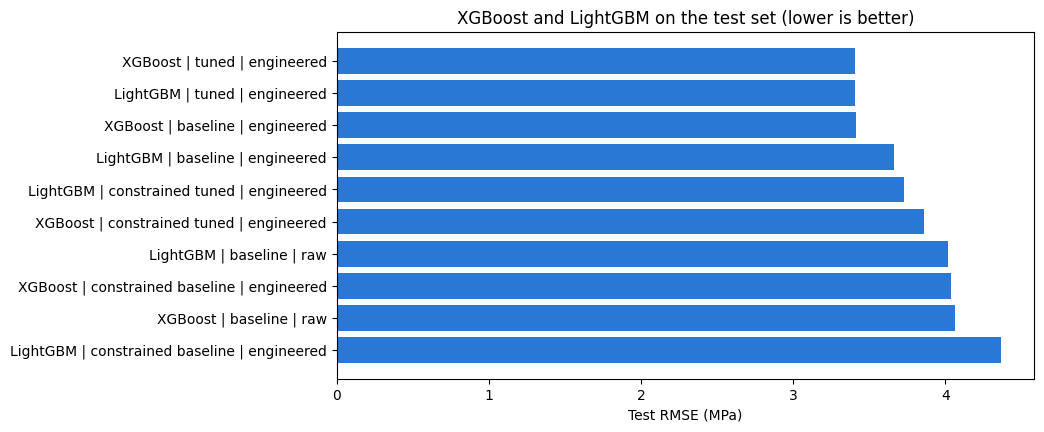

In [18]:
top = top_test.sort_values('Test_RMSE')
labels = top['model'] + ' | ' + top['stage'].str[2:] + ' | ' + top['features']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(labels[::-1], top['Test_RMSE'][::-1], color='#2a78d6')
ax.set_xlabel('Test RMSE (MPa)')
ax.set_title('XGBoost and LightGBM on the test set (lower is better)')
plt.show()

In [19]:
most_accurate = results.iloc[0]
physical = results[results['physics_OK']]
recommended = physical.iloc[0] if len(physical) else most_accurate

def describe(r):
    return (f"{r['model']} (constrained: {r['constrained']})  CV RMSE {r['CV_RMSE']:.2f}  "
            f"Test R2 {r['Test_R2']:.3f}  Test RMSE {r['Test_RMSE']:.2f} MPa  physics OK: {r['physics_OK']}")

print('Most accurate (CV):', describe(most_accurate))
print('Recommended for app:', describe(recommended))
print(f"\nCost of the physics constraints: {recommended['CV_RMSE'] - most_accurate['CV_RMSE']:+.3f} MPa CV RMSE")

Most accurate (CV): LightGBM (constrained: no)  CV RMSE 4.21  Test R2 0.953  Test RMSE 3.41 MPa  physics OK: False
Recommended for app: LightGBM (constrained: yes)  CV RMSE 4.35  Test R2 0.944  Test RMSE 3.73 MPa  physics OK: True

Cost of the physics constraints: +0.136 MPa CV RMSE


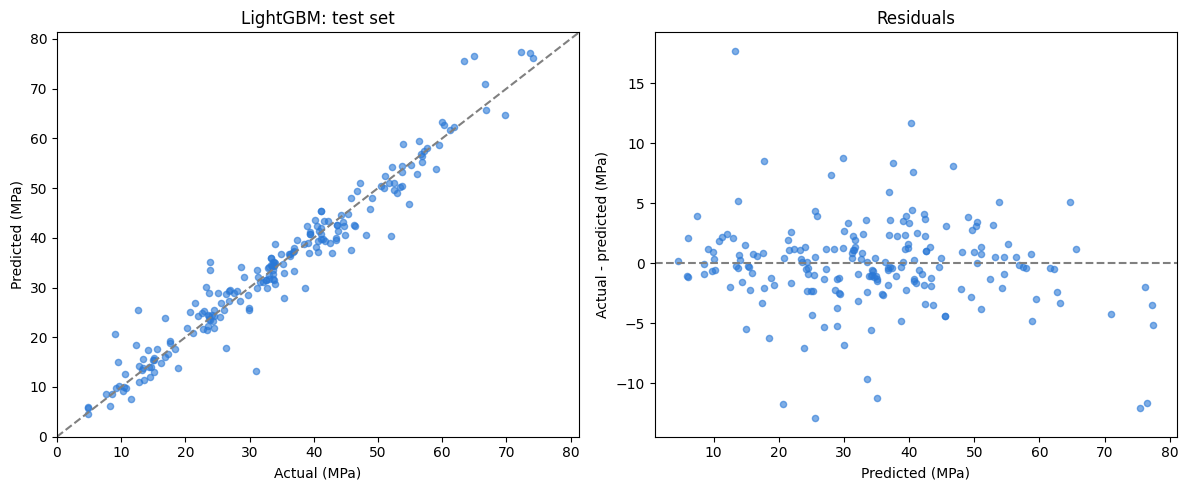

Within ±5 MPa: 87%   within ±10 MPa: 97%


In [20]:
model, pred = fitted[(recommended['model'], recommended['constrained'])]
resid = y_test - pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
lim = [0, max(y_test.max(), pred.max()) * 1.05]
ax1.plot(lim, lim, '--', color='grey')
ax1.scatter(y_test, pred, s=20, alpha=0.6, color='#2a78d6')
ax1.set(xlim=lim, ylim=lim, xlabel='Actual (MPa)', ylabel='Predicted (MPa)',
        title=f"{recommended['model']}: test set")
ax2.scatter(pred, resid, s=20, alpha=0.6, color='#2a78d6')
ax2.axhline(0, linestyle='--', color='grey')
ax2.set(xlabel='Predicted (MPa)', ylabel='Actual - predicted (MPa)', title='Residuals')
plt.tight_layout()
plt.show()

print(f'Within ±5 MPa: {(resid.abs() <= 5).mean():.0%}   within ±10 MPa: {(resid.abs() <= 10).mean():.0%}')

### 6.2 New mix designs: grouped-by-mix CV

The test split is by row, so most test rows are mixes the model already saw at another age. Here every row of a mix
is kept on the same side (5 folds over all 1005 rows, grouped by `mix_id`), so each mix is predicted **without
having seen it at any age**. This is the honest score for a brand-new mix design; expect it to be lower.

In [21]:
from sklearn.model_selection import GroupKFold

name, constrained = recommended['model'], recommended['constrained'] == 'yes'
params = tuned_params_c[name] if constrained else tuned_params[name]
scores = cross_validate(make_model(create(name, params, constrained)), data[FEATURES], data[TARGET],
                        groups=data['mix_id'], cv=GroupKFold(n_splits=5), n_jobs=-1,
                        scoring={'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'})
new_mix = {'R2': scores['test_R2'].mean(), 'RMSE': -scores['test_RMSE'].mean(), 'MAE': -scores['test_MAE'].mean()}

pd.DataFrame({'Known mix, new age (5-fold CV)': [recommended['CV_R2'], recommended['CV_RMSE'], recommended['CV_MAE']],
              'New mix design (grouped CV)': [new_mix['R2'], new_mix['RMSE'], new_mix['MAE']]},
             index=['R2', 'RMSE', 'MAE']).T

,R2,RMSE,MAE
"Known mix, new age (5-fold CV)",0.928,4.348,3.057
New mix design (grouped CV),0.900,5.068,3.594


---
## 7. Save the models

Both models are **refit on all 1005 rows** (train + test) so the app gets the most data;
the metrics stored with them are the CV and held-out test scores from above.

Each saved pipeline takes the 8 raw app inputs (feature engineering is its first step), with the same keys
`model_service.py` reads. The physics-constrained model is saved first; the unconstrained one follows in 7.1.
`MODELS` in `backend/model_service.py` lists the files the app loads.

In [22]:
import joblib
from sklearn.pipeline import Pipeline
from ML.features import ConcreteFeatures, sqrt_inverse

MODEL_FILE = 'concrete_strength_model_v3.joblib'

# sqrt_inverse (from ML.features, same as square_back) so the app can load the pickled model
steps = [('features', ConcreteFeatures())] if FEATURE_NAME == 'engineered' else []
steps.append(('model', TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), create(name, params, constrained)),
                                                  func=np.sqrt, inverse_func=sqrt_inverse, check_inverse=False)))
final_pipe = Pipeline(steps).fit(data[RAW_FEATURES], data[TARGET])

bundle = {
    'pipeline': final_pipe,
    'model_name': name,
    'constrained': constrained,
    'features': RAW_FEATURES,
    'feature_ranges': {c: {'min': float(data[c].min()), 'max': float(data[c].max())} for c in RAW_FEATURES},
    'best_params': params,
    'metrics': {'cv_R2': float(recommended['CV_R2']), 'cv_RMSE': float(recommended['CV_RMSE']),
                'test_R2': float(recommended['Test_R2']), 'test_RMSE': float(recommended['Test_RMSE']),
                'test_MAE': float(recommended['Test_MAE']),
                'new_mix_grouped_cv_R2': float(new_mix['R2']), 'new_mix_grouped_cv_RMSE': float(new_mix['RMSE'])},
    'trained_on': f'all {len(data)} rows (train + test)',
}
path = Path('models') / MODEL_FILE
joblib.dump(bundle, path)

# Reload check
loaded = joblib.load(path)
assert np.allclose(loaded['pipeline'].predict(test[RAW_FEATURES]), final_pipe.predict(test[RAW_FEATURES]))
print(f"Saved {path} ({path.stat().st_size / 1024:.0f} KB): {name}, constrained={constrained}")
print('Metrics:', {k: round(v, 3) for k, v in bundle['metrics'].items()})

Saved models\concrete_strength_model_v3.joblib (4566 KB): LightGBM, constrained=True
Metrics: {'cv_R2': 0.928, 'cv_RMSE': 4.348, 'test_R2': 0.944, 'test_RMSE': 3.727, 'test_MAE': 2.525, 'new_mix_grouped_cv_R2': 0.9, 'new_mix_grouped_cv_RMSE': 5.068}


### 7.1 Save the unconstrained model

The app lets the user switch between the physics-constrained model (above) and the most accurate unconstrained one.

Which unconstrained model? LightGBM wins on CV (4.21 vs 4.36 MPa) and the test set is a tie (3.41 vs 3.40 MPa),
but on **brand-new mix designs** (grouped-by-mix CV) XGBoost is clearly better (RMSE 4.84 vs 5.02 MPa).
New mixes are what the app is for, so **XGBoost** is saved. It does not pass the physics check (section 4.1);
that is the trade-off for its accuracy.

In [23]:
UNC_NAME = 'XGBoost'
UNC_FILE = 'concrete_strength_model_v3_unconstrained.joblib'

unc_params = tuned_params[UNC_NAME]
unc_row = results[(results['model'] == UNC_NAME) & (results['constrained'] == 'no')].iloc[0]

# New-mix score (grouped by mix, same folds as section 6.2)
scores = cross_validate(make_model(create(UNC_NAME, unc_params)), data[FEATURES], data[TARGET],
                        groups=data['mix_id'], cv=GroupKFold(n_splits=5), n_jobs=-1,
                        scoring={'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'})

steps = [('features', ConcreteFeatures())] if FEATURE_NAME == 'engineered' else []
steps.append(('model', TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), create(UNC_NAME, unc_params)),
                                                  func=np.sqrt, inverse_func=sqrt_inverse, check_inverse=False)))
unc_pipe = Pipeline(steps).fit(data[RAW_FEATURES], data[TARGET])

unc_bundle = {
    'pipeline': unc_pipe,
    'model_name': UNC_NAME,
    'constrained': False,
    'features': RAW_FEATURES,
    'feature_ranges': bundle['feature_ranges'],
    'best_params': unc_params,
    'metrics': {'cv_R2': float(unc_row['CV_R2']), 'cv_RMSE': float(unc_row['CV_RMSE']),
                'test_R2': float(unc_row['Test_R2']), 'test_RMSE': float(unc_row['Test_RMSE']),
                'test_MAE': float(unc_row['Test_MAE']),
                'new_mix_grouped_cv_R2': float(scores['test_R2'].mean()),
                'new_mix_grouped_cv_RMSE': float(-scores['test_RMSE'].mean())},
    'trained_on': f'all {len(data)} rows (train + test)',
}
unc_path = Path('models') / UNC_FILE
joblib.dump(unc_bundle, unc_path)
print(f"Saved {unc_path}: {UNC_NAME}, constrained=False")
print('Metrics:', {k: round(v, 3) for k, v in unc_bundle['metrics'].items()})

Saved models\concrete_strength_model_v3_unconstrained.joblib: XGBoost, constrained=False
Metrics: {'cv_R2': 0.927, 'cv_RMSE': 4.356, 'test_R2': 0.953, 'test_RMSE': 3.404, 'test_MAE': 2.278, 'new_mix_grouped_cv_R2': 0.909, 'new_mix_grouped_cv_RMSE': 4.843}
